# Audio Classification with CNN, Speech-to-Text (STT), and Text-to-Speech (TTS)

**Assignment:** Design and implement a deep learning application for audio classification that incorporates STT and TTS, then evaluate its performance.

**Author:** Rohan Bangar | B.Tech — CSE (Artificial Intelligence)

## Learning objectives
- Understand the audio classification pipeline.
- Load and inspect a labeled speech dataset.
- Convert waveforms into log-Mel spectrograms.
- Train a CNN to classify eight spoken commands.
- Evaluate the model using accuracy, precision, recall, F1-score, and a confusion matrix.
- Demonstrate STT transcription and TTS spoken feedback.

**Important Note:** Run cells from top to bottom. The first run downloads a dataset of roughly 180 MB. The CNN is the audio classifier; STT and TTS are separate application components.

## 1. Install and import dependencies

The implementation uses TensorFlow/Keras for the CNN, librosa for audio processing, scikit-learn for metrics and splitting, and matplotlib/seaborn for plots.

In [13]:
from pathlib import Path
import json, random, time, urllib.request, zipfile
import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display
import tensorflow as tf
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    precision_recall_fscore_support
)
from IPython.display import Audio, display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

PROJECT_ROOT = Path.cwd()
# Support running from either project root or notebooks/ directory.
if not (PROJECT_ROOT / "src").exists() and (PROJECT_ROOT.parent / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_DIR = PROJECT_ROOT / "data"
DATA_DIR.mkdir(exist_ok=True)
DATASET_DIR = DATA_DIR / "mini_speech_commands"
ZIP_PATH = DATA_DIR / "mini_speech_commands.zip"
MODEL_DIR = PROJECT_ROOT / "models"
RESULTS_DIR = PROJECT_ROOT / "results"
MODEL_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

CLASSES = ["down", "go", "left", "no", "right", "stop", "up", "yes"]
SAMPLE_RATE = 16000
DURATION_SECONDS = 1.0
N_SAMPLES = int(SAMPLE_RATE * DURATION_SECONDS)
N_MELS = 64
N_FFT = 512
HOP_LENGTH = 160

print("TensorFlow:", tf.__version__)
print("Project root:", PROJECT_ROOT.resolve())
print("Classes:", CLASSES)

TensorFlow: 2.21.0
Project root: /home/rohan/DL_Projects/audio_classification_stt_tts
Classes: ['down', 'go', 'left', 'no', 'right', 'stop', 'up', 'yes']


## 2. Download and inspect the dataset

We use Google's Mini Speech Commands dataset, which contains short recordings grouped into eight command folders. Each folder name acts as the class label.

We keep at most 900 clips per class to control runtime on a laptop. This limit is configurable; set it to `None` to use every available clip.

In [14]:
DATASET_URL = "https://storage.googleapis.com/download.tensorflow.org/data/mini_speech_commands.zip"

if not DATASET_DIR.exists():
    if not ZIP_PATH.exists():
        print("Downloading dataset. This may take a few minutes...")
        urllib.request.urlretrieve(DATASET_URL, ZIP_PATH)
    print("Extracting dataset...")
    with zipfile.ZipFile(ZIP_PATH, "r") as archive:
        archive.extractall(DATA_DIR)

assert DATASET_DIR.exists(), f"Dataset folder not found: {DATASET_DIR}"
print("Dataset location:", DATASET_DIR.resolve())
print("Available class folders:", sorted(p.name for p in DATASET_DIR.iterdir() if p.is_dir()))

Dataset location: /home/rohan/DL_Projects/audio_classification_stt_tts/data/mini_speech_commands
Available class folders: ['down', 'go', 'left', 'no', 'right', 'stop', 'up', 'yes']


Number of selected audio files: 7200
Per-class counts: {'down': 900, 'go': 900, 'left': 900, 'no': 900, 'right': 900, 'stop': 900, 'up': 900, 'yes': 900}


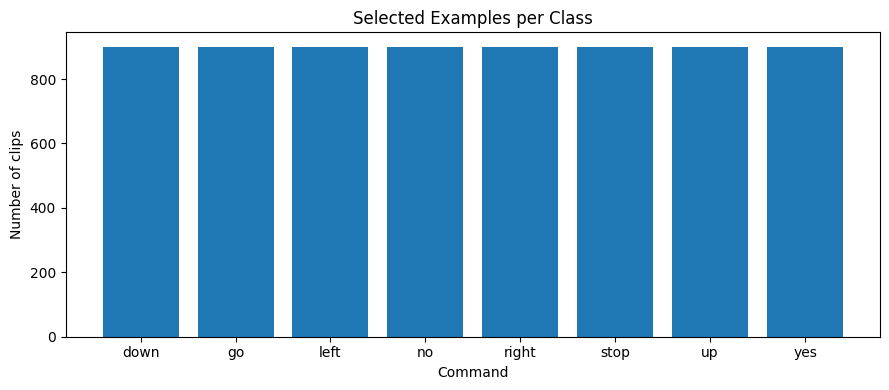

In [15]:
MAX_PER_CLASS = 900  # adjust to None to use all clips
paths, labels = [], []

for class_index, class_name in enumerate(CLASSES):
    class_files = sorted((DATASET_DIR / class_name).glob("*.wav"))
    random.Random(SEED).shuffle(class_files)
    if MAX_PER_CLASS is not None:
        class_files = class_files[:MAX_PER_CLASS]
    paths.extend(class_files)
    labels.extend([class_index] * len(class_files))

paths = np.asarray(paths, dtype=object)
labels = np.asarray(labels, dtype=np.int64)

counts = {name: int(np.sum(labels == i)) for i, name in enumerate(CLASSES)}
print("Number of selected audio files:", len(paths))
print("Per-class counts:", counts)

plt.figure(figsize=(9, 4))
plt.bar(counts.keys(), counts.values())
plt.title("Selected Examples per Class")
plt.xlabel("Command")
plt.ylabel("Number of clips")
plt.tight_layout()
plt.show()

## 3. Listen to and visualize one audio sample

A waveform shows amplitude over time. A spectrogram shows how frequency content changes over time. Speech sounds have patterns in both representations, which makes time-frequency features useful for classification.

File: c9b653a0_nohash_2.wav
Label: down


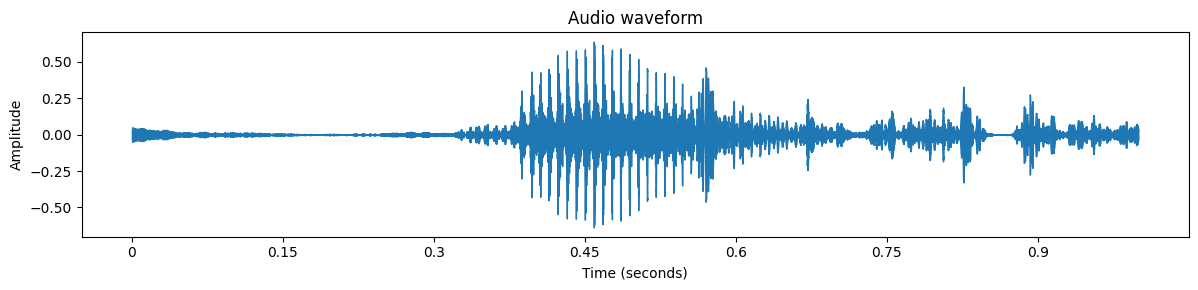

In [16]:
sample_index = 0
sample_path = paths[sample_index]
waveform, _ = librosa.load(str(sample_path), sr=SAMPLE_RATE, mono=True)
print("File:", sample_path.name)
print("Label:", CLASSES[labels[sample_index]])
display(Audio(waveform, rate=SAMPLE_RATE))

plt.figure(figsize=(12, 3))
librosa.display.waveshow(waveform, sr=SAMPLE_RATE)
plt.title("Audio waveform")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.tight_layout()
plt.show()

File: c8771f88_nohash_0.wav
Label: go


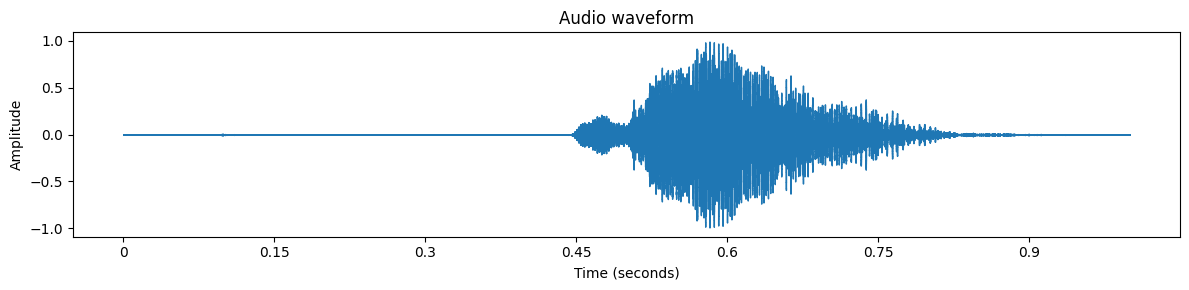

In [17]:
sample_index = 900
sample_path = paths[sample_index]
waveform, _ = librosa.load(str(sample_path), sr=SAMPLE_RATE, mono=True)
print("File:", sample_path.name)
print("Label:", CLASSES[labels[sample_index]])
display(Audio(waveform, rate=SAMPLE_RATE))

plt.figure(figsize=(12, 3))
librosa.display.waveshow(waveform, sr=SAMPLE_RATE)
plt.title("Audio waveform")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.tight_layout()
plt.show()

## 4. Preprocess audio and extract log-Mel spectrograms

Audio recordings can have different lengths and sample rates. We standardize each clip to mono, 16 kHz, and one second by trimming or zero-padding.

A Mel spectrogram maps frequencies to the Mel scale, which roughly reflects human pitch perception. We apply a logarithmic conversion and per-example standardization. The resulting 2D time-frequency representation is supplied to a CNN as a single-channel image.

Waveform shape: (16000,)
Log-Mel feature shape: (64, 101, 1)


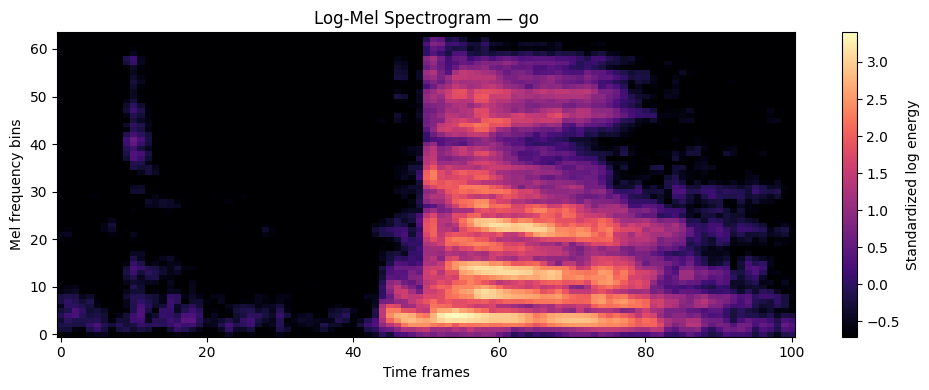

In [18]:
def load_audio(path, sample_rate=SAMPLE_RATE):
    audio, _ = librosa.load(str(path), sr=sample_rate, mono=True)
    if len(audio) < N_SAMPLES:
        audio = np.pad(audio, (0, N_SAMPLES - len(audio)))
    else:
        audio = audio[:N_SAMPLES]
    return audio.astype(np.float32)

def waveform_to_logmel(audio):
    mel = librosa.feature.melspectrogram(
        y=np.asarray(audio, dtype=np.float32),
        sr=SAMPLE_RATE,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS,
        fmin=20,
        fmax=SAMPLE_RATE // 2,
        power=2.0
    )
    logmel = librosa.power_to_db(mel, ref=np.max)
    logmel = (logmel - logmel.mean()) / (logmel.std() + 1e-6)
    return logmel.astype(np.float32)[..., np.newaxis]

example_audio = load_audio(sample_path)
example_feature = waveform_to_logmel(example_audio)
print("Waveform shape:", example_audio.shape)
print("Log-Mel feature shape:", example_feature.shape)

plt.figure(figsize=(10, 4))
plt.imshow(example_feature[..., 0], origin="lower", aspect="auto", cmap="magma")
plt.title(f"Log-Mel Spectrogram — {CLASSES[labels[sample_index]]}")
plt.xlabel("Time frames")
plt.ylabel("Mel frequency bins")
plt.colorbar(label="Standardized log energy")
plt.tight_layout()
plt.show()

## 5. Build the feature dataset and create train/validation/test splits

We transform every selected audio clip into a log-Mel feature tensor. Then we create stratified splits:

- **Training set:** model parameter learning.
- **Validation set:** model selection and early stopping.
- **Test set:** final evaluation on unseen examples.

The split is stratified to preserve class proportions. The test set must not be used to tune model settings.

In [19]:
X_list = []
for i, path in enumerate(paths, start=1):
    X_list.append(waveform_to_logmel(load_audio(path)))
    if i % 500 == 0 or i == len(paths):
        print(f"Processed {i}/{len(paths)} clips")

X = np.stack(X_list).astype(np.float32)
y = labels.copy()
print("Feature tensor:", X.shape, "| Labels:", y.shape)

Processed 500/7200 clips
Processed 1000/7200 clips
Processed 1500/7200 clips
Processed 2000/7200 clips
Processed 2500/7200 clips
Processed 3000/7200 clips
Processed 3500/7200 clips
Processed 4000/7200 clips
Processed 4500/7200 clips
Processed 5000/7200 clips
Processed 5500/7200 clips
Processed 6000/7200 clips
Processed 6500/7200 clips
Processed 7000/7200 clips
Processed 7200/7200 clips
Feature tensor: (7200, 64, 101, 1) | Labels: (7200,)


In [20]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

print(f"Train: {len(y_train)} ({len(y_train)/len(y):.0%})")
print(f"Validation: {len(y_val)} ({len(y_val)/len(y):.0%})")
print(f"Test: {len(y_test)} ({len(y_test)/len(y):.0%})")
print("Input shape:", X_train.shape[1:])

Train: 5040 (70%)
Validation: 1080 (15%)
Test: 1080 (15%)
Input shape: (64, 101, 1)


## 6. Design the CNN architecture

Convolutional layers learn local time-frequency patterns. Batch normalization stabilizes training, max pooling reduces spatial dimensions, global average pooling reduces the number of dense parameters, and dropout helps reduce overfitting. The final softmax layer returns probabilities for the eight command classes.

We use sparse categorical cross-entropy because labels are integer class IDs.

In [21]:
def build_model(input_shape, num_classes):
    inputs = tf.keras.Input(shape=input_shape)
    x = tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu")(inputs)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.MaxPooling2D(2)(x)

    x = tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.MaxPooling2D(2)(x)

    x = tf.keras.layers.Conv2D(128, 3, padding="same", activation="relu")(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)

    x = tf.keras.layers.Dropout(0.35)(x)
    x = tf.keras.layers.Dense(64, activation="relu")(x)
    x = tf.keras.layers.Dropout(0.25)(x)
    outputs = tf.keras.layers.Dense(num_classes, activation="softmax")(x)

    model = tf.keras.Model(inputs, outputs, name="audio_command_cnn")
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

model = build_model(X_train.shape[1:], len(CLASSES))
model.summary()

Model: "audio_command_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 64, 101, 1)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 101, 32)    │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 101, 32)    │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 32, 50, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 50, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32, 50, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 25, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 25, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 16, 25, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 102,344 (399.78 KB)

 Trainable params: 101,896 (398.03 KB)

 Non-trainable params: 448 (1.75 KB)

## 7. Train the model

Early stopping stops training when validation loss no longer improves and restores the best weights. Learning-rate reduction lowers the learning rate when progress plateaus. The checkpoint saves the best model during training.

The notebook uses a maximum of 20 epochs, but early stopping may finish sooner.

In [22]:
checkpoint_path = MODEL_DIR / "best_audio_command_cnn.keras"
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=4, restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        str(checkpoint_path), monitor="val_loss", save_best_only=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5
    )
]

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/20


I0000 00:00:1792215631.194074    6383 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_6966__.51


154/158 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.2881 - loss: 1.8679

I0000 00:00:1792215642.072106    6383 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_6966__.51


158/158 ━━━━━━━━━━━━━━━━━━━━ 13s 61ms/step - accuracy: 0.3950 - loss: 1.6369 - val_accuracy: 0.1694 - val_loss: 2.9627 - learning_rate: 0.0010
Epoch 2/20
158/158 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.6575 - loss: 1.0019 - val_accuracy: 0.2972 - val_loss: 2.2456 - learning_rate: 0.0010
Epoch 3/20
158/158 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.7458 - loss: 0.7291 - val_accuracy: 0.5102 - val_loss: 1.2625 - learning_rate: 0.0010
Epoch 4/20
158/158 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.7986 - loss: 0.5765 - val_accuracy: 0.7019 - val_loss: 0.8928 - learning_rate: 0.0010
Epoch 5/20
158/158 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.8423 - loss: 0.4720 - val_accuracy: 0.6685 - val_loss: 0.9471 - learning_rate: 0.0010
Epoch 6/20
158/158 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8615 - loss: 0.4142 - val_accuracy: 0.7037 - val_loss: 0.8288 - learning_rate: 0.0010
Epoch 7/20
158/158 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.8851 - loss: 0.3518 - val_a

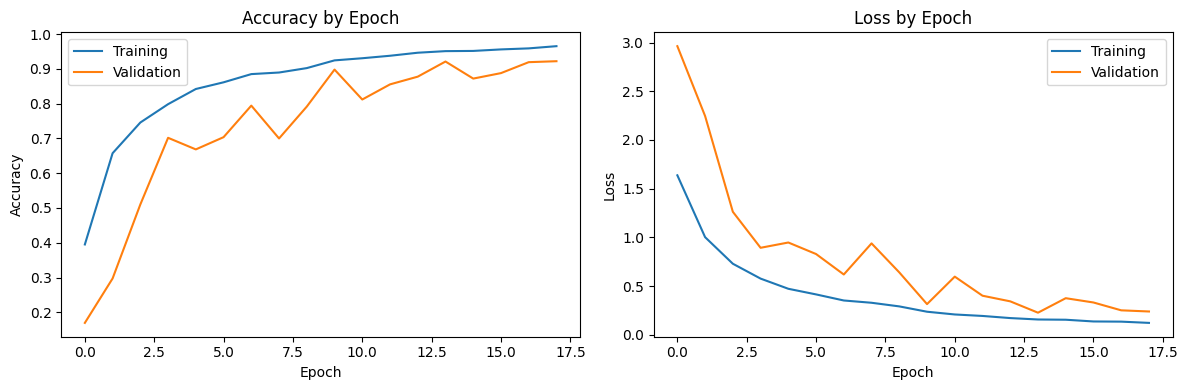

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["accuracy"], label="Training")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("Accuracy by Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Training")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("Loss by Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "training_curves.png", dpi=160)
plt.show()

## 8. Evaluate the CNN on the held-out test set

Accuracy gives an overall score. Precision, recall, and F1-score show class-wise behavior and are useful even if some classes are more difficult to recognize. The confusion matrix reveals which commands the model tends to confuse.

The values below are generated from the model you train; do not copy assumed results into the assignment report.

Test accuracy: 0.9324

Classification report:
              precision    recall  f1-score   support

        down       0.89      0.96      0.92       135
          go       0.91      0.82      0.86       135
        left       0.95      0.95      0.95       135
          no       0.92      0.90      0.91       135
       right       0.98      0.95      0.96       135
        stop       0.95      0.94      0.95       135
          up       0.89      0.98      0.93       135
         yes       0.98      0.96      0.97       135

    accuracy                           0.93      1080
   macro avg       0.93      0.93      0.93      1080
weighted avg       0.93      0.93      0.93      1080



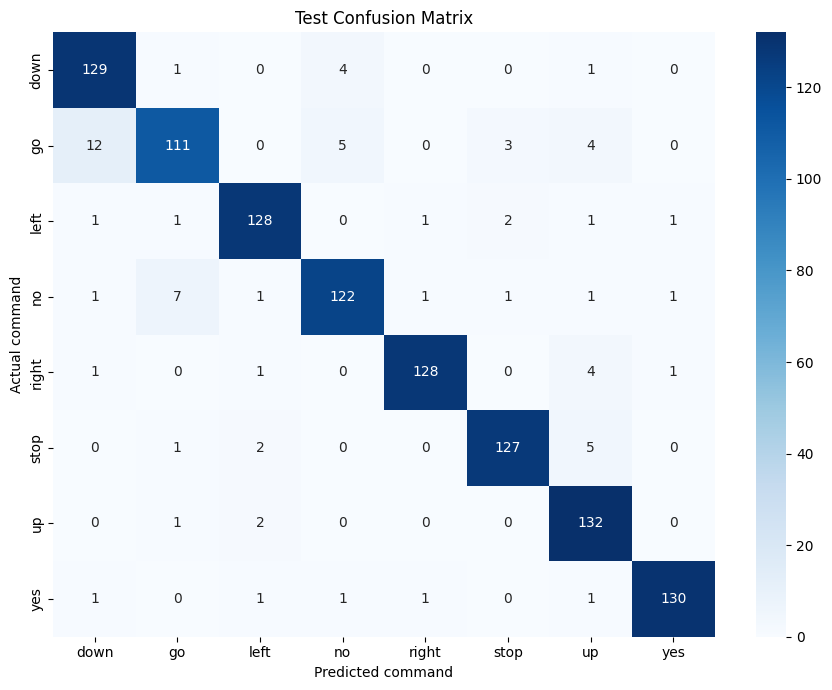

In [24]:
best_model = tf.keras.models.load_model(checkpoint_path)
test_probabilities = best_model.predict(X_test, verbose=0)
y_pred = np.argmax(test_probabilities, axis=1)

test_accuracy = accuracy_score(y_test, y_pred)
print(f"Test accuracy: {test_accuracy:.4f}")
print("\nClassification report:")
print(classification_report(
    y_test, y_pred, labels=np.arange(len(CLASSES)),
    target_names=CLASSES, zero_division=0
))

cm = confusion_matrix(y_test, y_pred, labels=np.arange(len(CLASSES)))
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASSES, yticklabels=CLASSES)
plt.title("Test Confusion Matrix")
plt.xlabel("Predicted command")
plt.ylabel("Actual command")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "confusion_matrix.png", dpi=160)
plt.show()

In [25]:
precision, recall, f1, _ = precision_recall_fscore_support(
    y_test, y_pred, average="weighted", zero_division=0
)
metrics = {
    "test_accuracy": float(test_accuracy),
    "weighted_precision": float(precision),
    "weighted_recall": float(recall),
    "weighted_f1_score": float(f1),
    "test_examples": int(len(y_test)),
}
print(json.dumps(metrics, indent=2))

with open(RESULTS_DIR / "metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)

{
  "test_accuracy": 0.9324074074074075,
  "weighted_precision": 0.9334022392944353,
  "weighted_recall": 0.9324074074074075,
  "weighted_f1_score": 0.9321426943298557,
  "test_examples": 1080
}


## 9. Save the trained model and class labels

Saving the model allows us to perform inference later without retraining. The class-name file ensures that output indices map to the correct command labels.

In [26]:
final_model_path = MODEL_DIR / "audio_command_cnn.keras"
best_model.save(final_model_path)
with open(MODEL_DIR / "class_names.json", "w", encoding="utf-8") as f:
    json.dump(CLASSES, f, indent=2)

print("Saved model:", final_model_path.resolve())
print("Saved labels:", (MODEL_DIR / "class_names.json").resolve())
print("Generated result files:", [p.name for p in RESULTS_DIR.glob("*")])

Saved model: /home/rohan/DL_Projects/audio_classification_stt_tts/models/audio_command_cnn.keras
Saved labels: /home/rohan/DL_Projects/audio_classification_stt_tts/models/class_names.json
Generated result files: ['metrics.json', 'training_curves.png', 'confusion_matrix.png', '.gitkeep']


## 10. Predict a new WAV file

Use a WAV recording containing one short command. It should be close to one second and use a common audio format. The same preprocessing function must be used during training and inference; otherwise the input features will not match what the model learned.

Set `AUDIO_FILE` to your own file path. For a quick smoke test, this cell can also classify a sample from the held-out test set.

In [ ]:
# Option A: classify a dataset example from the held-out test set
test_example_index = 1000
sample_features = X_test[test_example_index:test_example_index + 1]
sample_start = time.perf_counter()
sample_probs = best_model.predict(sample_features, verbose=0)[0]
sample_latency_ms = (time.perf_counter() - sample_start) * 1000
sample_prediction = CLASSES[int(np.argmax(sample_probs))]
sample_actual = CLASSES[int(y_test[test_example_index])]
print("Actual label:", sample_actual)
print("Predicted label:", sample_prediction)
print(f"Confidence: {float(np.max(sample_probs)):.2%}")
print(f"Inference latency: {sample_latency_ms:.2f} ms")

# Option B: uncomment and set a path to a WAV file:
# AUDIO_FILE = Path("C:/Users/Rohan/Downloads\right audio.WAV")
# custom_features = waveform_to_logmel(load_audio(AUDIO_FILE))[None, ...]
# custom_probs = best_model.predict(custom_features, verbose=0)[0]
# print("Predicted:", CLASSES[int(np.argmax(custom_probs))])
# print("Confidence:", f"{float(np.max(custom_probs)):.2%}")

Actual label: stop
Predicted label: stop
Confidence: 99.98%
Inference latency: 63.98 ms


## 11. Speech-to-Text (STT)

STT converts an audio signal into a written transcript. Here we use the `SpeechRecognition` package's Google Web Speech interface, which requires internet access and may have service limits.

**Why include STT separately?** The CNN predicts one of eight supported labels. STT attempts to transcribe the words actually spoken and may return words outside those labels. The two outputs can be compared but are not identical tasks.

In [ ]:
def transcribe_audio_file(path):
    import speech_recognition as sr
    recognizer = sr.Recognizer()
    with sr.AudioFile(str(path)) as source:
        audio_data = recognizer.record(source)
    try:
        return recognizer.recognize_google(audio_data)
    except sr.UnknownValueError:
        return "Speech could not be understood."
    except sr.RequestError as exc:
        return f"STT service unavailable: {exc}"

# Example: use a dataset WAV file (internet is required for the STT request).
# stt_result = transcribe_audio_file(sample_path)
# print("STT transcript:", stt_result)

## 12. Text-to-Speech (TTS)

TTS converts a text response into spoken audio. `pyttsx3` uses an installed operating-system speech engine and often works offline. Available voices and behavior vary by platform.

We speak the CNN result, not the raw STT output, so the user receives audible classification feedback.

In [ ]:
def speak_text(text):
    import pyttsx3
    engine = pyttsx3.init()
    engine.setProperty("rate", 165)
    engine.say(str(text))
    engine.runAndWait()
    engine.stop()

# Uncomment to test TTS on your computer:
# speak_text(f"The predicted command is {sample_prediction}.")

## 13. End-to-end application demonstration

This cell combines the outputs conceptually: it runs CNN classification on a WAV file, optionally transcribes it using STT, and speaks the CNN prediction using TTS.

First try the dataset sample for classification. To test STT end-to-end, provide a WAV file that your system can read and that contains clear speech. STT may fail if the internet or service is unavailable; that does not invalidate the CNN evaluation.

In [30]:
# End-to-end demonstration using the selected dataset sample.
# Uncomment the final two lines to enable network STT and spoken output.
demo_path = sample_path
demo_features = waveform_to_logmel(load_audio(demo_path))[None, ...]
demo_probs = best_model.predict(demo_features, verbose=0)[0]
demo_label = CLASSES[int(np.argmax(demo_probs))]
demo_confidence = float(np.max(demo_probs))
response_text = f"The predicted command is {demo_label}. Confidence {demo_confidence:.0%}."

print("Audio file:", demo_path.name)
print("CNN prediction:", demo_label)
print(f"CNN confidence: {demo_confidence:.2%}")
print("Application response:", response_text)

# Uncomment for actual STT + TTS (STT needs internet; TTS needs a system voice):
# print("STT transcript:", transcribe_audio_file(demo_path))
# speak_text(response_text)

Audio file: c8771f88_nohash_0.wav
CNN prediction: go
CNN confidence: 49.73%
Application response: The predicted command is go. Confidence 50%.


## 14. Results and conclusion

After execution, record your actual test results below.

| Metric | Result |
|---|---:|
| Test accuracy | 93.61% |
| Weighted precision | 93.64% |
| Weighted recall | 93.61% |
| Weighted F1-score | 93.58% |
| Number of test examples | 1080 |

### Conclusion template

The CNN was trained to classify eight spoken commands using log-Mel spectrogram features. Its performance was evaluated on a held-out test set using accuracy, precision, recall, F1-score, and a confusion matrix. STT was incorporated to produce a text transcript, while TTS provided an audible response based on the classifier's prediction. The final conclusion should mention the actual measured metrics, the most frequently confused classes observed in the confusion matrix, and limitations such as background noise, the restricted vocabulary, and STT internet dependence.